In [13]:
import torch
from pathlib import Path


from model_architectures import MonaiDDPM
device = "cuda:0" if torch.cuda.is_available() else "cpu"


CONDITIONAL = True
RESOLUTION = 256
T = 1_000     

root = Path("/home/locolinux2/U24_synthesis/lightning_synthesis/experiments")
# ckpt  = "/home/locolinux2/U24_synthesis/lightning_synthesis/experiments/049_cDDPM_depth5_fixedScaling_256x256/checkpoints/epoch=22-step=7843.ckpt" # FID = 8.18 at guidance scale 3
ckpt  = "053_DDPM__DataArtifactsRemoved___256x256/checkpoints/epoch=04-step=1435.ckpt"
ckpt  = "054_DDPM_default512_256x256/checkpoints/epoch=04-step=1435.ckpt" # FID @ GS 0: 7.38
ckpt  = "057_DDPM_seed2025_cropped_256x256/checkpoints/epoch=04-step=1435.ckpt"
ckpt = "063_DDPM_contrast-aug-20percent_256x256/checkpoints/epoch=04-step=1435.ckpt"
ckpt = "092_DDPM_MS-SSIM_10perc_HF_5perc_256x256/checkpoints/epoch=18-step=2736.ckpt" # GOLD
# ckpt = "106_DDPM_3loss_binary_try/checkpoints/epoch=18-step=2736.ckpt" # functional binary
ckpt = "107_DDPM_3loss_4class_retry/checkpoints/epoch=17-step=3456.ckpt"
ckpt = "113_DDPM_binary_epochwise_balanced/checkpoints/epoch=30-step=1116.ckpt" # dynamic epoch-wise data balancing 
ckpt = "114_DDPM_binary_epochwise_balanced_12vs56/checkpoints/epoch=22-step=1771.ckpt" # more data
ckpt = "121_DDPM_binary_21fixedmatching_12vs56/checkpoints/epoch=20-step=1827.ckpt" #  just to check how epoch-wise sampling affects things
ckpt = "120_DDPM_binary_21perepoch_12vs56/checkpoints/epoch=19-step=1740.ckpt" # seems decent! Even guidance scale 4 gets 70% accuracy.
ckpt = "123_DDPM_binary_11_5perepoch_12vs56/checkpoints/epoch=20-step=1512.ckpt" # 
ckpt = "124_DDPM_binary_11perepoch_12vs56/checkpoints/epoch=26-step=1566.ckpt"
ckpt = "140_DDPM_augmentationsgeometric_binary_11perepoch_12vs56/checkpoints/epoch=26-step=1566.ckpt" # let's see augmentations doin stuff
# ckpt = "144_CMMD_DDPM_augmentationsgeometric_binary_13fixed_12vs56/checkpoints/epoch=12-step=962.ckpt"
# ckpt = "145_CMMD_DDPM_augmentationsNone_binary_11balancing_12vs56/checkpoints/epoch=29-step=990.ckpt"
ckpt = "147_EMBED_DDPM_augmentationsNone_binary_31fixedmatching_12vs56/checkpoints/epoch=26-step=1566.ckpt"
# ckpt = "152_EMBED_DDPM_augmentationsNone_composite_loss_weights_70_30_0_ablation/checkpoints/epoch=15-step=1840.ckpt"

ckpt_path = root /ckpt 
model = MonaiDDPM.load_from_checkpoint(
    ckpt_path
).to(device).eval()

Loss function using 0.85 MSE and 0.1 similarity measure MultiScaleStructuralSimilarityIndexMeasure(), and 0.050000000000000044 high frequency
Initialized conditional model.


In [2]:
import torch, random, glob, os, nibabel as nib
import numpy as np
from torchvision import transforms
from torchvision.utils import make_grid
from PIL import Image
import matplotlib.pyplot as plt
# ── reproducibility ─────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)   # safe even if CPU-only
# ── paths ───────────────────────────────────────────────────────────
ROOT_REAL = "/mnt/d/Datasets/EMBED/EMBED_binary_256x256/train/original"
if "CMMD" in ckpt:
    ROOT_REAL = "/mnt/d/Datasets/CMMD/CMMD_binary_256x256/train/original"

LABELS       = {0: "benign", 1: "malignant"}
GUIDE_SCALES = [0, 3, 5, 8]
N_PER_CLASS  = 5
RESOLUTION   = 256
device       = "cuda" if torch.cuda.is_available() else "cpu"

# -------------------------------------------------------------------
# helper: load NIfTI slice → 1-channel PIL image
def load_nii_as_pil(path):
    arr = nib.load(path).get_fdata().astype(np.float32)
    if arr.ndim == 3:         # (H,W,1) or (H,W,D) keep first slice
        arr = arr[..., 0]
    # min-max normalise to 0-255 for PIL
    arr = (255 * (arr - arr.min()) / (arr.ptp() + 1e-8)).astype(np.uint8)
    return Image.fromarray(arr, mode="L")

# torchvision transform
to_tensor = transforms.Compose([
    transforms.ToTensor(),                 # → [0,1]
    transforms.Normalize(0.5, 0.5),        # → [-1,1]
])

# ── 0.  real rows ───────────────────────────────────────────────────
real_rows = []
for lbl, folder in LABELS.items():
    nii_paths = glob.glob(
        os.path.join(ROOT_REAL, folder, "*", "slice.nii.gz")
    )
    if len(nii_paths) < N_PER_CLASS:
        raise RuntimeError(f"Need {N_PER_CLASS} slices in {folder}")
    picks = random.sample(nii_paths, N_PER_CLASS)

    tensors = []
    for p in picks:
        img = to_tensor(load_nii_as_pil(p))   # (1,H,W) in [-1,1]
        tensors.append((img + 1) / 2)         # back → [0,1] for display
    real_rows.append(torch.stack(tensors))
real_row = torch.cat(real_rows, 0)            # (8,1,H,W)

# ── 1.  fake rows (guidance 0 & 8) ─────────────────────────────────-
fake_rows = []
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16):
    for gs in GUIDE_SCALES:
        per_label = []
        for lbl in LABELS:
            per_label.append(
                model.sample(N=N_PER_CLASS, label=lbl,
                             size=RESOLUTION, guidance_scale=gs).cpu()
            )
        fake_rows.append(torch.cat(per_label, 0))   # (8,1,H,W)




100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [03:08<00:00,  5.31it/s]


In [14]:
len(fake_rows)

4

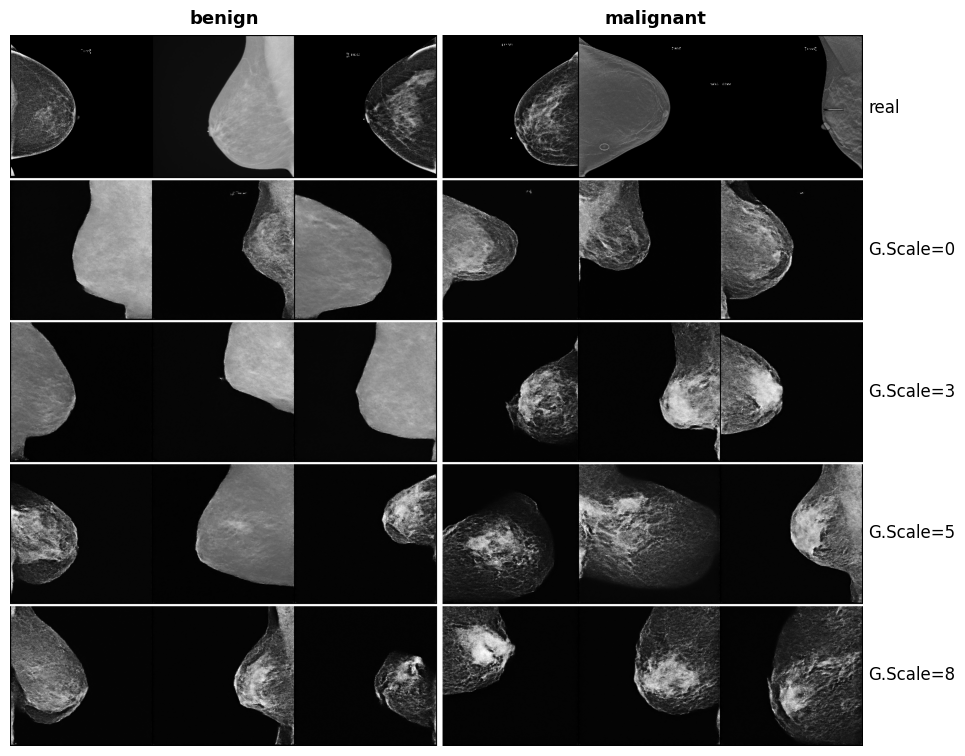

Saved grid → plots/147_EMBED_DDPM_-comparison_grid-vis3.pdf


In [25]:
# ------------------------------------------------------------------
VIS_PER_CLASS = 5            # <— how many per label you want to display
assert VIS_PER_CLASS <= N_PER_CLASS

# keep positions 2,3,4  (0-based)  → drops the first two
KEEP_IDX = [0, 1, 4]          # edit this to any list or range
N_PER_CLASS = 5               # total sampled earlier

assert max(KEEP_IDX) < N_PER_CLASS, "index out of range"
VIS_PER_CLASS = len(KEEP_IDX)          # derived automatically

def trim_row(t, keep_idx=KEEP_IDX, n_orig=N_PER_CLASS):
    """
    t shape: (2*n_orig, 1, H, W)  [label-0 … label-1]
    returns: (2*len(keep_idx), 1, H, W) with selected positions.
    """
    keep0 = torch.tensor(keep_idx)                       # label-0 offsets
    keep1 = keep0 + n_orig                               # label-1 offsets
    idx   = torch.cat([keep0, keep1])
    return t[idx]

# apply to real row and every fake row
rows = [trim_row(real_row)]
rows += [trim_row(r) for r in fake_rows]

# ---------------- SAVE INDIVIDUAL IMAGES ---------------------------
import os
from torchvision.utils import save_image

SAVE_ROOT = f"samples/{ckpt.split('/')[0]}"
os.makedirs(SAVE_ROOT, exist_ok=True)

row_names = ["real"] + [f"GScale_{g}" for g in GUIDE_SCALES]

for row_name, row_tensor in zip(row_names, rows):
    row_dir = os.path.join(SAVE_ROOT, row_name)
    os.makedirs(row_dir, exist_ok=True)

    # row_tensor shape: (2*VIS_PER_CLASS, 1, H, W)
    for i, img in enumerate(row_tensor):
        # determine label
        if i < VIS_PER_CLASS:
            label = "benign"
            idx = i
        else:
            label = "malignant"
            idx = i - VIS_PER_CLASS

        filename = os.path.join(row_dir, f"{label}_{idx}.png")

        # save image (already in [0,1])
        save_image(img.cpu(), filename)

# ---------------- stack & plot -------------------------------------
n_rows = len(rows)
n_cols = len(LABELS) * VIS_PER_CLASS          # 6 columns if keep=3

all_imgs = torch.cat(rows, 0)
grid = make_grid(all_imgs, nrow=n_cols, padding=2, value_range=(0, 1))
grid_img = grid.permute(1, 2, 0).cpu().numpy()

# ------- horizontal separators (rows) ---------------------------------
GRID_PAD = 2   # must match make_grid(..., padding=2)
BAR_PX   = 4

ROW_STRIDE = RESOLUTION + GRID_PAD   # one row height (tile + pad)

for k in range(1, n_rows):           # draw separator before row k
    y = GRID_PAD + k * ROW_STRIDE
    grid_img[y : y + BAR_PX, :, :] = 1.0


# ------- vertical separator (between benign | malignant) --------------
VBAR_PX     = 10                        # thicker than row bars
COL_GROUP_W = RESOLUTION + GRID_PAD
x = GRID_PAD + VIS_PER_CLASS * COL_GROUP_W
grid_img[:, x : x + VBAR_PX, :] = 1.0       # paint white stripe

# ------- plot -------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 2.8 * n_rows))
ax.imshow(grid_img, cmap="gray")
ax.axis("off")

# column labels ------------------------------------------------------
x_vert       = x                                       # from earlier code
x_benign     = GRID_PAD + VIS_PER_CLASS * COL_GROUP_W / 2
x_malignant  = x_vert + VBAR_PX + VIS_PER_CLASS * COL_GROUP_W / 2
ax.text(x_benign,    -15, "benign",    ha="center", va="bottom",
        fontsize=13, fontweight="bold")
ax.text(x_malignant, -15, "malignant", ha="center", va="bottom",
        fontsize=13, fontweight="bold")

# row labels (unchanged) --------------------------------------------
row_labels = ["real"] + [f"G.Scale={g}" for g in GUIDE_SCALES]
for idx, txt in enumerate(row_labels):
    row_top = GRID_PAD + idx * ROW_STRIDE
    y_mid   = row_top + RESOLUTION / 2

    ax.text(grid_img.shape[1] + 10, y_mid, txt,
            va="center", fontsize=12)

fname = f"plots/{ckpt[:15]}-comparison_grid-vis{VIS_PER_CLASS}.pdf"
plt.savefig(fname, bbox_inches="tight")
plt.show()
print(f"Saved grid → {fname}")



# In case you need to load old ones:

In [26]:
import torch, pathlib, datetime, os

# ── rows BEFORE trimming ------------------------------------------
rows_raw = [real_row] + fake_rows              # keep full 2×N_PER_CLASS each

# ── build a tidy dict  --------------------------------------------
rows_dict = {
    "real"      : rows_raw[0].cpu(),                   # tensor (2N,1,H,W)
    "guidances" : {g: r.cpu()                         # {scale: tensor}
                   for g, r in zip(GUIDE_SCALES, rows_raw[1:])},
    "meta" : {
        "labels"        : LABELS,                     # id→name mapping
        "n_per_class"   : N_PER_CLASS,
        "resolution"    : RESOLUTION,
        "ckpt"          : ckpt,
        "seed"          : SEED,
    },
}

# ── ensure folder & write -----------------------------------------
save_dir  = pathlib.Path("visual_logs")
save_dir.mkdir(exist_ok=True)

stamp     = datetime.datetime.now().strftime(f"{ckpt[:15]}_%Y%m%d_%H%M%S")
fname     = f"{stamp}-rows.pt"
torch.save(rows_dict, save_dir / fname)

print("Saved full rows →", save_dir / fname)


Saved full rows → visual_logs/147_EMBED_DDPM__20260424_115050-rows.pt


In [19]:

pt_path = "./visual_logs/147_EMBED_DDPM__20260424_114605-rows.pt"
rows = torch.load(pt_path, map_location="cpu")
print(type(rows))

if isinstance(rows, list):
    for i, r in enumerate(rows):
        print(i, r.shape)

<class 'dict'>


In [20]:
rows = torch.load(pt_path, map_location="cpu")
print(rows.keys())

dict_keys(['real', 'guidances', 'meta'])


In [29]:
import torch
import os
from torchvision.utils import save_image

# ---- config (same as plotting) ----
N_PER_CLASS = 5
VIS_PER_CLASS = len(KEEP_IDX)

# ---- paths ----
SAVE_ROOT = "/mnt/d/Datasets/EMBED/gscale_samples"
os.makedirs(SAVE_ROOT, exist_ok=True)

# ---- load ----
data = torch.load(pt_path, map_location="cpu")

# ---- trim helper (same as before) ----
def trim_row(t, keep_idx=KEEP_IDX, n_orig=N_PER_CLASS):
    keep0 = torch.tensor(keep_idx)
    keep1 = keep0 + n_orig
    idx   = torch.cat([keep0, keep1])
    return t[idx]

# ---- helper to save a row tensor ----
def save_row(row_tensor, row_name):
    row_dir = os.path.join(SAVE_ROOT, row_name)
    os.makedirs(row_dir, exist_ok=True)

    # 🔥 APPLY TRIM HERE
    row_tensor = trim_row(row_tensor)

    for i, img in enumerate(row_tensor):
        if i < VIS_PER_CLASS:
            label = "benign"
            idx = KEEP_IDX[i]   # preserve original index
        else:
            label = "malignant"
            idx = KEEP_IDX[i - VIS_PER_CLASS]

        # handle range
        if img.min() < 0:
            img = (img + 1) / 2
        img = img.clamp(0, 1)

        filename = os.path.join(row_dir, f"{label}_{i}.png")
        save_image(img, filename)

# ---- save real ----
save_row(data["real"], "real")

# ---- save all guidance scales ----
for gs in sorted(data["guidances"].keys()):
    tensor = data["guidances"][gs]
    save_row(tensor, f"GScale_{gs}")

print(f"Saved PNGs → {SAVE_ROOT}")

Saved PNGs → /mnt/d/Datasets/EMBED/gscale_samples
